In [148]:
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt

## dataset:
    https://www.kaggle.com/datasets/jithinanievarghese/drugs-side-effects-and-medical-condition
## problem:
     Healthcare professionals must choose medications that effectively treat a patient's medical condition while minimizing harmful side effects.
     With thousands of available drugs the ability to identify what drugs are most suitable can be challenging. This mostly due to human errors or
     confusion of what the actual medical drug do?

## goalis:
     Predict the most appropriate drug for a medical condition
     Identify drugs that should be avoided because of severe side effects
     Assist healthcare professionals in making safer prescription decisions.

## target type:
     Classification

## questions I want answered from EDA:
     1-Which medical conditions have the largest number of available drugs?
     2-What are the most common side effects ?and what drug perduces the least side effects?
     3-Which drugs should be avoided because they frequently produce severe side effects?
     4-How does ratings vary across the available drugs and medical conditions?
     5-How much overlap exists between the two datasets, and how reliably can medications and medical conditions be matched?


In [149]:
pd.set_option('display.max_columns', None)# disables Max default columns

df=pd.read_csv(r"C:\Users\abdal\PycharmProjects\AI_EDA\EDA_Project_Drugs\DataSet\drugs_side_effects_drugs_com.csv")

## Understanding data / data Loading & Structure

In [150]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2931 entries, 0 to 2930
Data columns (total 17 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   drug_name                      2931 non-null   object 
 1   medical_condition              2931 non-null   object 
 2   side_effects                   2807 non-null   object 
 3   generic_name                   2888 non-null   object 
 4   drug_classes                   2849 non-null   object 
 5   brand_names                    1718 non-null   object 
 6   activity                       2931 non-null   object 
 7   rx_otc                         2930 non-null   object 
 8   pregnancy_category             2702 non-null   object 
 9   csa                            2931 non-null   object 
 10  alcohol                        1377 non-null   object 
 11  related_drugs                  1462 non-null   object 
 12  medical_condition_description  2931 non-null   o

In [151]:
df.describe()

,rating,no_of_reviews
count,1586.000000,1586.000000
mean,6.812926,75.064943
std,2.313044,184.900847
min,0.000000,1.000000
25%,5.600000,2.000000
50%,7.000000,12.000000
75%,8.500000,58.000000
max,10.000000,2934.000000


In [152]:
df.shape

(2931, 17)

In [153]:
df.size

49827

In [154]:
df.columns

Index(['drug_name', 'medical_condition', 'side_effects', 'generic_name',
       'drug_classes', 'brand_names', 'activity', 'rx_otc',
       'pregnancy_category', 'csa', 'alcohol', 'related_drugs',
       'medical_condition_description', 'rating', 'no_of_reviews', 'drug_link',
       'medical_condition_url'],
      dtype='object')

In [155]:
df.head()

,drug_name,medical_condition,side_effects,generic_name,drug_classes,brand_names,activity,rx_otc,pregnancy_category,csa,alcohol,related_drugs,medical_condition_description,rating,no_of_reviews,drug_link,medical_condition_url
0,doxycycline,Acne,"(hives, difficult breathing, swelling in your ...",doxycycline,"Miscellaneous antimalarials, Tetracyclines","Acticlate, Adoxa CK, Adoxa Pak, Adoxa TT, Alod...",87%,Rx,D,N,X,amoxicillin: https://www.drugs.com/amoxicillin...,Acne Other names: Acne Vulgaris; Blackheads; B...,6.8,760.0,https://www.drugs.com/doxycycline.html,https://www.drugs.com/condition/acne.html
1,spironolactone,Acne,hives ; difficulty breathing; swelling of your...,spironolactone,"Aldosterone receptor antagonists, Potassium-sp...","Aldactone, CaroSpir",82%,Rx,C,N,X,amlodipine: https://www.drugs.com/amlodipine.h...,Acne Other names: Acne Vulgaris; Blackheads; B...,7.2,449.0,https://www.drugs.com/spironolactone.html,https://www.drugs.com/condition/acne.html
2,minocycline,Acne,"skin rash, fever, swollen glands, flu-like sym...",minocycline,Tetracyclines,"Dynacin, Minocin, Minolira, Solodyn, Ximino, V...",48%,Rx,D,N,NaN,amoxicillin: https://www.drugs.com/amoxicillin...,Acne Other names: Acne Vulgaris; Blackheads; B...,5.7,482.0,https://www.drugs.com/minocycline.html,https://www.drugs.com/condition/acne.html
3,Accutane,Acne,problems with your vision or hearing; muscle o...,isotretinoin (oral),"Miscellaneous antineoplastics, Miscellaneous u...",NaN,41%,Rx,X,N,X,doxycycline: https://www.drugs.com/doxycycline...,Acne Other names: Acne Vulgaris; Blackheads; B...,7.9,623.0,https://www.drugs.com/accutane.html,https://www.drugs.com/condition/acne.html
4,clindamycin,Acne,hives ; difficult breathing; swelling of your ...,clindamycin topical,"Topical acne agents, Vaginal anti-infectives","Cleocin T, Clindacin ETZ, Clindacin P, Clindag...",39%,Rx,B,N,NaN,doxycycline: https://www.drugs.com/doxycycline...,Acne Other names: Acne Vulgaris; Blackheads; B...,7.4,146.0,https://www.drugs.com/mtm/clindamycin-topical....,https://www.drugs.com/condition/acne.html


In [156]:
df.nunique()


drug_name                        2912
medical_condition                  47
side_effects                     2759
generic_name                     1392
drug_classes                      274
brand_names                      1552
activity                           93
rx_otc                              3
pregnancy_category                  6
csa                                 7
alcohol                             1
related_drugs                     535
medical_condition_description      47
rating                             86
no_of_reviews                     301
drug_link                        2931
medical_condition_url              47
dtype: int64

### Checking missing values

In [157]:
df.isnull().sum()

drug_name                           0
medical_condition                   0
side_effects                      124
generic_name                       43
drug_classes                       82
brand_names                      1213
activity                            0
rx_otc                              1
pregnancy_category                229
csa                                 0
alcohol                          1554
related_drugs                    1469
medical_condition_description       0
rating                           1345
no_of_reviews                    1345
drug_link                           0
medical_condition_url               0
dtype: int64

## Data Cleaning And Reasons and Creating Target

In [158]:
print("-----------------Missing Values precentile---------------------")
print(df.isnull().mean()*100)

print("number of duplicates:",df.duplicated().sum())

print()

df_cleaning=df.copy()

-----------------Missing Values precentile---------------------
drug_name                         0.000000
medical_condition                 0.000000
side_effects                      4.230638
generic_name                      1.467076
drug_classes                      2.797680
brand_names                      41.385193
activity                          0.000000
rx_otc                            0.034118
pregnancy_category                7.813033
csa                               0.000000
alcohol                          53.019447
related_drugs                    50.119413
medical_condition_description     0.000000
rating                           45.888775
no_of_reviews                    45.888775
drug_link                         0.000000
medical_condition_url             0.000000
dtype: float64
number of duplicates: 0



In [159]:
print("Shape before cleaning:",df_cleaning.shape)

Shape before cleaning: (2931, 17)


In [160]:
df_cleaning=df_cleaning.dropna(subset="side_effects")#removing missing values <5%

df_cleaning=df_cleaning.drop(columns=["alcohol"]) #dropping the column since it isn't needed and lacks information (only info is x)
df_cleaning=df_cleaning.drop(columns=["drug_link"]) #dropping the column since it isn't needed and lacks information (only url)
df_cleaning=df_cleaning.drop(columns=["medical_condition_url"]) #dropping the column since it isn't needed and lacks information (only url)

df_cleaning["brand_names"]=df_cleaning["brand_names"].fillna("Unknown") #even though above 5% data might be used when integrating with the other data set so replacing missing values to Unknown

df_cleaning["related_drugs"]=df_cleaning["related_drugs"].fillna("NA") #even though above 5% data is important filled with NA(since its important data)

df_cleaning["pregnancy_category"]=df_cleaning["pregnancy_category"].fillna("Unknown") #even though above 5% data is important filled with NA(since its important data)

df_cleaning.dropna(subset=["no_of_reviews"],inplace=True)#removing the reviews samples and by doing so removes rating aswell

#df_cleaning=df_cleaning.fillna("Unknown")#instead of removing important samples (which we alrdy done before) the precentile is low for both so replace them with unknown
df_cleaning["generic_name"]=df_cleaning["generic_name"].fillna("Unknown") #even though above 5% data is important filled with NA(since its important data)

df_cleaning["drug_classes"]=df_cleaning["drug_classes"].fillna("Unknown")

print("Shape after cleaning",df_cleaning.shape)

print("-----------------Missing Values precentile---------------------")

print(df_cleaning.isnull().mean()*100)

#df_cleaning=df_cleaning.dropna(subset="rx_otc")

#df_cleaning=df_cleaning.dropna(subset="alcohol",axis=0)

Shape after cleaning (1562, 14)
-----------------Missing Values precentile---------------------
drug_name                        0.0
medical_condition                0.0
side_effects                     0.0
generic_name                     0.0
drug_classes                     0.0
brand_names                      0.0
activity                         0.0
rx_otc                           0.0
pregnancy_category               0.0
csa                              0.0
related_drugs                    0.0
medical_condition_description    0.0
rating                           0.0
no_of_reviews                    0.0
dtype: float64


In [161]:
df_cleaning["medical_condition_description"].tail(200)

2461    Pain An unpleasant sensory and emotional exper...
2463    Pain An unpleasant sensory and emotional exper...
2468    Pain An unpleasant sensory and emotional exper...
2469    Pain An unpleasant sensory and emotional exper...
2470    Pain An unpleasant sensory and emotional exper...
                              ...                        
2921    Weight Loss (Obesity/Overweight) More than hal...
2922    Weight Loss (Obesity/Overweight) More than hal...
2923    Weight Loss (Obesity/Overweight) More than hal...
2924    Weight Loss (Obesity/Overweight) More than hal...
2926    Weight Loss (Obesity/Overweight) More than hal...
Name: medical_condition_description, Length: 200, dtype: object

### Checking for Outliers and creating new features

In [162]:
lst=["rating","no_of_reviews"]
for col in lst:
    df_cleaning[f"new_{col}"]=pd.to_numeric(df_cleaning[col], errors='coerce')
    Q1=df_cleaning[f"new_{col}"].quantile(0.25)
    Q3=df_cleaning[f"new_{col}"].quantile(0.75)
    IQR=Q3-Q1
    print("Q1=",Q1)
    print("Q3=",Q3)
    print("IQR=",IQR)
    lb=Q1-1.5*IQR
    ub=Q3+1.5*IQR
    outliers=(df_cleaning[f"new_{col}"]<lb) | (df_cleaning[f"new_{col}"]>ub)
    print("outliers=",outliers.sum())
    #there are outliers in both the rating is 68 and the no_of_reviews is 208
    #though my virdict can't be done until visualizing them in a box

Q1= 5.6
Q3= 8.5
IQR= 2.9000000000000004
outliers= 68
Q1= 3.0
Q3= 59.75
IQR= 56.75
outliers= 208


 there are outliers in both the rating (is 68) and the no_of_reviews (is 208)
 though my virdict can't be done until visualizing them in a box

In [163]:
print("new Shape:",df_cleaning.shape)

new Shape: (1562, 16)


In [164]:
df_cleaning.columns

Index(['drug_name', 'medical_condition', 'side_effects', 'generic_name',
       'drug_classes', 'brand_names', 'activity', 'rx_otc',
       'pregnancy_category', 'csa', 'related_drugs',
       'medical_condition_description', 'rating', 'no_of_reviews',
       'new_rating', 'new_no_of_reviews'],
      dtype='object')

--------------Visualization related to Outliers determination--------------


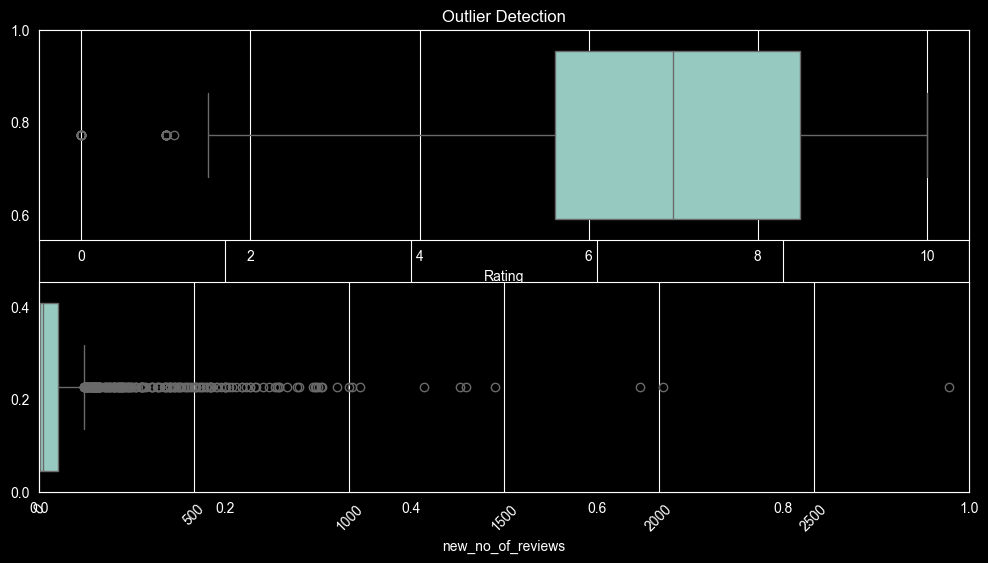

In [165]:
print("--------------Visualization related to Outliers determination--------------")

plt.figure(figsize=(12,6))

plt.title("Outlier Detection")

plt.subplot(2,1,1)

sb.boxplot(x=df_cleaning["new_rating"])

plt.xlabel("Rating")

plt.subplot(2,1,2)

sb.boxplot(x=df_cleaning["new_no_of_reviews"])

plt.xlim((0,3000))

plt.xticks(range(0,3000,500))

plt.xticks(rotation=45)

plt.show()

as seen from the plot theoutliers are true values since ratings and reviews can differ between each drug and each person
that is why some values reach 3000 in reviews or 2 in ratings
also from observing the plot we can tell that are no invalid values such as negative numbers.

                   drug_name medical_condition  new_no_of_reviews
2908             phentermine       Weight Loss             2934.0
2920  bupropion / naltrexone       Weight Loss             2013.0
2910                Contrave       Weight Loss             1939.0
523             escitalopram           Anxiety             1471.0
2917                 Saxenda       Weight Loss             1377.0
1036               bisacodyl      Constipation             1357.0
2862          nitrofurantoin               UTI             1242.0
518                buspirone           Anxiety             1034.0
2008                zolpidem          Insomnia             1008.0


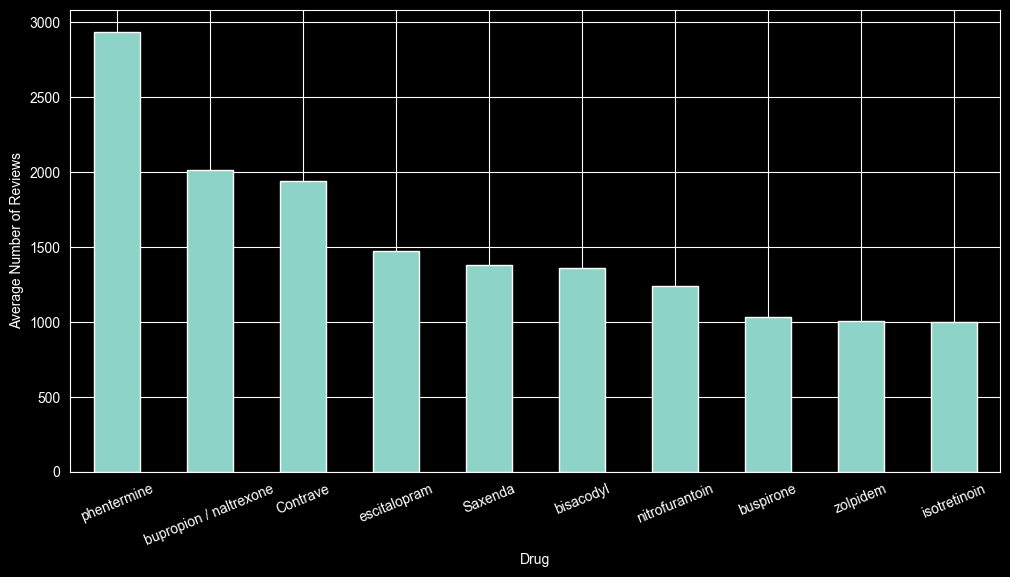

In [166]:
plt.figure(figsize=(12,6))

print(df_cleaning[df_cleaning["new_no_of_reviews"] > 1000][["drug_name","medical_condition","new_no_of_reviews"]].sort_values("new_no_of_reviews",ascending=False))

#checking if reviews above 1000 are real.

df_cleaning.groupby(["drug_name"])["new_no_of_reviews"].mean().sort_values(ascending=False).head(10).plot(kind="bar")

plt.xlabel("Drug")

plt.xticks(rotation=22.5)

plt.ylabel("Average Number of Reviews")

plt.show()

#ploting the drugs to review to check if a single drug can have multi reviews

#as seen from the plot we can tell that each drug has its own reviews and rating and based on what kind of drug it is it can have multiple reviews that is why it spiked to 3000

#also by the plot you can tell there is no invalid values but still requires studying
df_cleaning.to_csv("cleaned_drugs_side_effects_drugs_com.csv",index=False)



as seen from the plot we can tell that each drug has its own reviews and rating and based on what kind of drug it is it can have multiple reviews that is why it spiked to 3000

### Creating a Save of The cleaned Dataset

In [167]:
df_cleaning.to_csv("cleaned_drugs.csv",index=False)

### Calling said dataset

In [168]:
dfcleaned=pd.read_csv(r"C:\Users\abdal\PycharmProjects\AI_EDA\EDA_Project_Drugs\DataSet\cleaned_drugs.csv")
print(df.columns)

Index(['drug_name', 'medical_condition', 'side_effects', 'generic_name',
       'drug_classes', 'brand_names', 'activity', 'rx_otc',
       'pregnancy_category', 'csa', 'alcohol', 'related_drugs',
       'medical_condition_description', 'rating', 'no_of_reviews', 'drug_link',
       'medical_condition_url'],
      dtype='object')


### Checking Balance


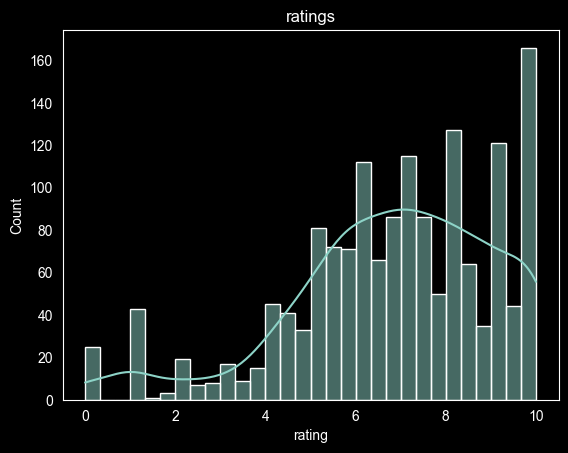

In [169]:
plt.figure()
plt.title("ratings")
sb.histplot(dfcleaned["rating"],bins=30,kde=True)
plt.grid()
plt.show()

In [170]:
dfcleaned["rating"].skew().round(2)

np.float64(-0.81)

ratings are imbalanced with a skew of 0.82 leanig to the left .

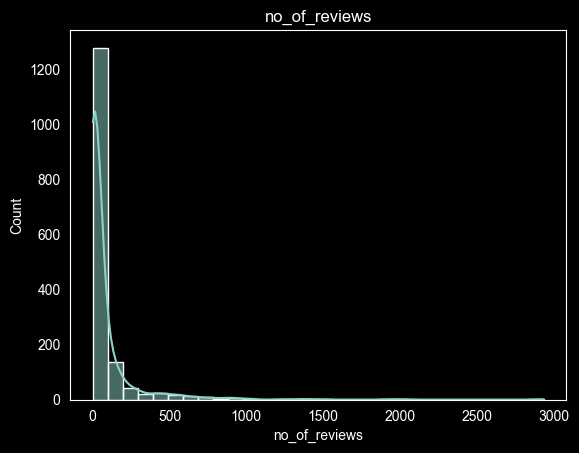

In [171]:
plt.figure()
plt.title("no_of_reviews")
sb.histplot(dfcleaned["no_of_reviews"],bins=30,kde=True)
plt.grid()
plt.show()

In [172]:
dfcleaned["no_of_reviews"].skew().round(2)

np.float64(6.11)

as we can see that the reviews amount is imbalanced with a slight skew to right of 6.14

In [173]:
dfcleaned["rx_otc"].value_counts(normalize=True) * 100

rx_otc
Rx        80.985915
Rx/OTC    11.843790
OTC        7.170294
Name: proportion, dtype: float64

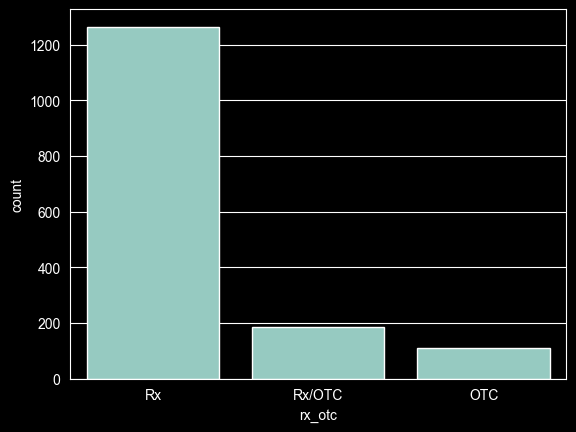

In [174]:
sb.countplot(data=dfcleaned, x="rx_otc")
plt.show()

data is imbalance, which makes total sense because most of the patients require a prescription to get there drugs

## Answering Questions:

### 1-Which medical conditions have the largest number of available drugs?

medical_condition
Hypertension            126
Acne                    115
Pain                     99
Diabetes (Type 2)        85
Osteoarthritis           69
AIDS/HIV                 65
Hayfever                 59
ADHD                     51
Insomnia                 50
Migraine                 50
Depression               46
Anxiety                  44
Bipolar Disorder         44
GERD (Heartburn)         44
Colds & Flu              41
Psoriasis                39
Diabetes (Type 1)        38
Eczema                   36
Asthma                   33
Bronchitis               33
Osteoporosis             32
Seizures                 32
Constipation             32
Cholesterol              30
Rheumatoid Arthritis     24
UTI                      20
Angina                   20
COPD                     20
Diarrhea                 19
Weight Loss              18
Incontinence             17
Covid 19                 15
Hypothyroidism           14
Schizophrenia            13
Alzheimer's              12
Er

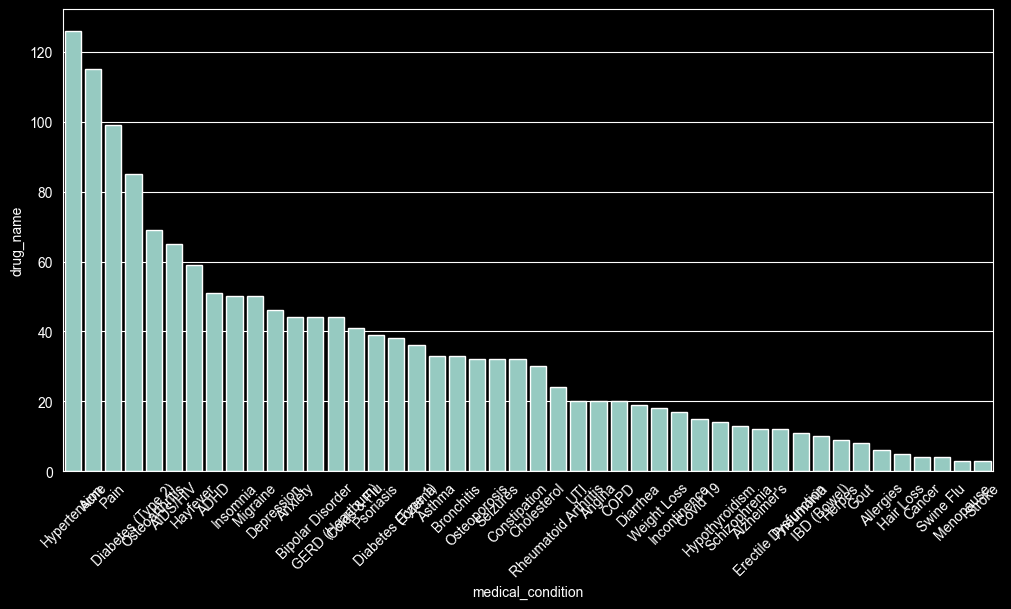

In [175]:
a=dfcleaned.groupby('medical_condition')['drug_name'].nunique().sort_values(ascending=False)
print(a)#colds & Flu have the largest
plt.figure(figsize=(12,6))
sb.barplot(a)
plt.xticks(rotation=45)
plt.show()
#the medical cond that has the largest amount of drugs would be Cold and the Flu .
#due to it being a common symptoms,and are what companies and pharmacitical the most.

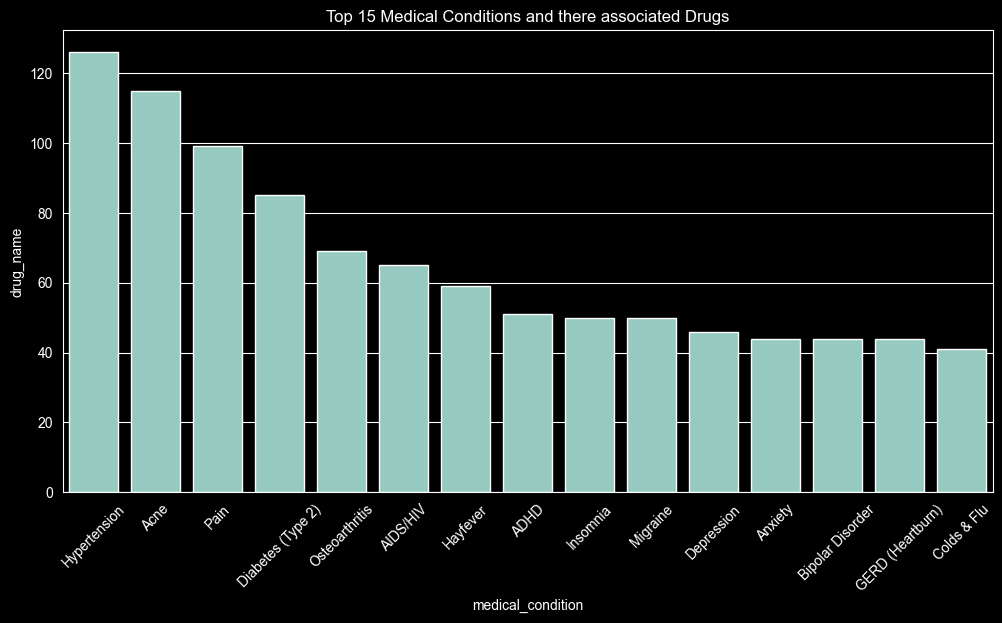

In [176]:
plt.figure(figsize=(12,6))
plt.title("Top 15 Medical Conditions and there associated Drugs")
sb.barplot(a.head(15))
plt.xticks(rotation=45)
plt.show()

 the medical condition that has the largest amount of drugs would be Cold and the Flu .
 due to it being a common symptom and are what medicinal companies target the most in terms of business


-0.04333383188883929


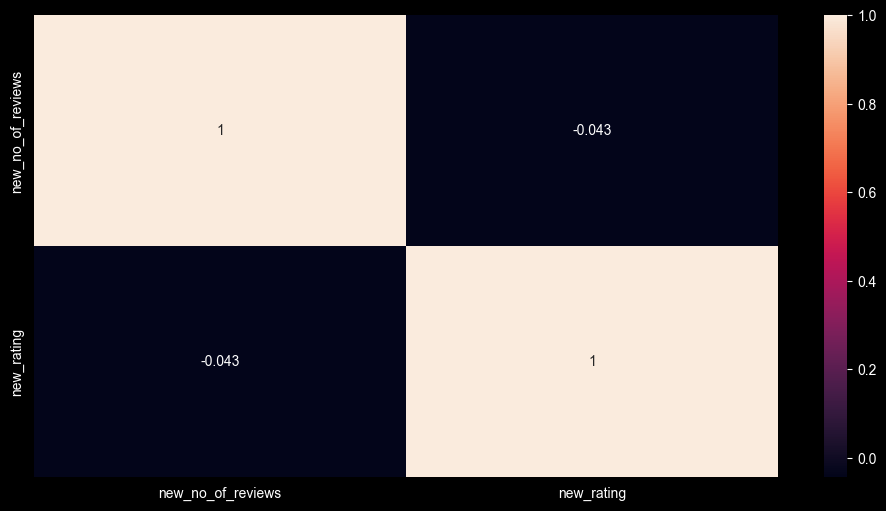

In [177]:
print(dfcleaned["new_rating"].corr(dfcleaned["new_no_of_reviews"]))#weak negative correlation

plt.figure(figsize=(12,6))
sb.heatmap(dfcleaned[["new_no_of_reviews","new_rating"]].corr(),annot=True)
plt.show()


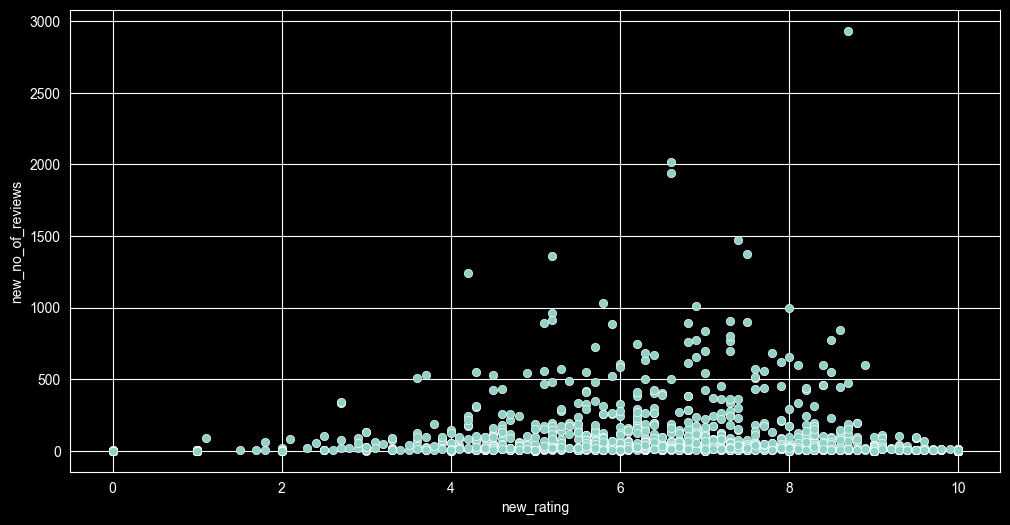

In [178]:
plt.figure(figsize=(12,6))

sb.scatterplot(y=dfcleaned["new_no_of_reviews"], x=dfcleaned["new_rating"])
plt.show()

 Most records have relatively few reviews, while a small number have many reviews across different rating levels

In [179]:
# Pearson: measures linear correlation
pearson_corr = dfcleaned["new_rating"].corr(
    dfcleaned["new_no_of_reviews"],
    method="pearson"
)
pearson_corr

np.float64(-0.04333383188883929)

The correlation between rating and number of reviews is -0.043, indicating a very weak negative linear relationship..


### 2-What are the most common side effects ?and what drug perduces the least side effects?

In [180]:
sideeffects = dfcleaned["side_effects"].sort_values(
    ascending=True
)
sideeffects

415     ( hives , difficult breathing, swelling in you...
401     ( hives , difficult breathing, swelling in you...
194     ( hives , difficult breathing, swelling in you...
702     ( hives , difficult breathing, swelling in you...
758     ( hives , difficult breathing, swelling in you...
                              ...                        
1290    urinating less than usual or not at all; muscl...
1402    vision problems, changes in color vision; seve...
1403    vision problems, changes in color vision; seve...
987     worsening chest pain; pounding heartbeats or f...
983     worsening chest pain; pounding heartbeats or f...
Name: side_effects, Length: 1562, dtype: object

In [181]:
# Keep records that have side-effect descriptions
side_effects_long = (
    dfcleaned[["drug_name", "side_effects"]].copy()
)
side_effects_long

,drug_name,side_effects
0,doxycycline,"(hives, difficult breathing, swelling in your ..."
1,spironolactone,hives ; difficulty breathing; swelling of your...
2,minocycline,"skin rash, fever, swollen glands, flu-like sym..."
3,Accutane,problems with your vision or hearing; muscle o...
4,clindamycin,hives ; difficult breathing; swelling of your ...
...,...,...
1557,phentermine / topiramate,"mood or behavior changes, anxiety , panic atta..."
1558,Bontril PDM,"Along with its needed effects, a medicine may ..."
1559,chorionic gonadotropin (hcg),hives ; difficult breathing; swelling of your ...
1560,Lomaira,hives ; difficult breathing; swelling of your ...


In [182]:
# Preserve the original row ID so we can count records correctly
side_effects_long["record_id"] = side_effects_long.index
side_effects_long

,drug_name,side_effects,record_id
0,doxycycline,"(hives, difficult breathing, swelling in your ...",0
1,spironolactone,hives ; difficulty breathing; swelling of your...,1
2,minocycline,"skin rash, fever, swollen glands, flu-like sym...",2
3,Accutane,problems with your vision or hearing; muscle o...,3
4,clindamycin,hives ; difficult breathing; swelling of your ...,4
...,...,...,...
1557,phentermine / topiramate,"mood or behavior changes, anxiety , panic atta...",1557
1558,Bontril PDM,"Along with its needed effects, a medicine may ...",1558
1559,chorionic gonadotropin (hcg),hives ; difficult breathing; swelling of your ...,1559
1560,Lomaira,hives ; difficult breathing; swelling of your ...,1560


In [183]:
# spliting and filtering side effects
side_effects_long["side_effect"] = (side_effects_long["side_effects"].astype(str).str.lower().str.strip(" ()[]{}").str.split(r"\s*[;,]\s*")
)
side_effects_long

,drug_name,side_effects,record_id,side_effect
0,doxycycline,"(hives, difficult breathing, swelling in your ...",0,"[hives, difficult breathing, swelling in your ..."
1,spironolactone,hives ; difficulty breathing; swelling of your...,1,"[hives, difficulty breathing, swelling of your..."
2,minocycline,"skin rash, fever, swollen glands, flu-like sym...",2,"[skin rash, fever, swollen glands, flu-like sy..."
3,Accutane,problems with your vision or hearing; muscle o...,3,"[problems with your vision or hearing, muscle ..."
4,clindamycin,hives ; difficult breathing; swelling of your ...,4,"[hives, difficult breathing, swelling of your ..."
...,...,...,...,...
1557,phentermine / topiramate,"mood or behavior changes, anxiety , panic atta...",1557,"[mood or behavior changes, anxiety, panic atta..."
1558,Bontril PDM,"Along with its needed effects, a medicine may ...",1558,"[along with its needed effects, a medicine may..."
1559,chorionic gonadotropin (hcg),hives ; difficult breathing; swelling of your ...,1559,"[hives, difficult breathing, swelling of your ..."
1560,Lomaira,hives ; difficult breathing; swelling of your ...,1560,"[hives, difficult breathing, swelling of your ..."


In [184]:
# Put each individual effect into its own row
side_effects_long = side_effects_long.explode("side_effect")
side_effects_long

,drug_name,side_effects,record_id,side_effect
0,doxycycline,"(hives, difficult breathing, swelling in your ...",0,hives
0,doxycycline,"(hives, difficult breathing, swelling in your ...",0,difficult breathing
0,doxycycline,"(hives, difficult breathing, swelling in your ...",0,swelling in your face or throat) or a severe s...
0,doxycycline,"(hives, difficult breathing, swelling in your ...",0,sore throat
0,doxycycline,"(hives, difficult breathing, swelling in your ...",0,burning in your eyes
...,...,...,...,...
1561,benzphetamine,hives ; difficulty breathing; swelling of your...,1561,increased sweating
1561,benzphetamine,hives ; difficulty breathing; swelling of your...,1561,dry mouth or an unpleasant taste in your mouth
1561,benzphetamine,hives ; difficulty breathing; swelling of your...,1561,nausea
1561,benzphetamine,hives ; difficulty breathing; swelling of your...,1561,diarrhea upset stomach


In [185]:
# Cleaning
side_effects_long["side_effect"] = (side_effects_long["side_effect"].str.strip(" \t\n.,;:()[]{}"))
side_effects_long

,drug_name,side_effects,record_id,side_effect
0,doxycycline,"(hives, difficult breathing, swelling in your ...",0,hives
0,doxycycline,"(hives, difficult breathing, swelling in your ...",0,difficult breathing
0,doxycycline,"(hives, difficult breathing, swelling in your ...",0,swelling in your face or throat) or a severe s...
0,doxycycline,"(hives, difficult breathing, swelling in your ...",0,sore throat
0,doxycycline,"(hives, difficult breathing, swelling in your ...",0,burning in your eyes
...,...,...,...,...
1561,benzphetamine,hives ; difficulty breathing; swelling of your...,1561,increased sweating
1561,benzphetamine,hives ; difficulty breathing; swelling of your...,1561,dry mouth or an unpleasant taste in your mouth
1561,benzphetamine,hives ; difficulty breathing; swelling of your...,1561,nausea
1561,benzphetamine,hives ; difficulty breathing; swelling of your...,1561,diarrhea upset stomach


In [186]:
# Remove empty terms
side_effects_long = side_effects_long[side_effects_long["side_effect"].ne("")]

In [187]:
side_effect_counts = (side_effects_long.drop_duplicates(["record_id", "side_effect"])["side_effect"].value_counts())

In [188]:
print("Top 10 most frequently mentioned side-effect terms:")
print(side_effect_counts.head(10))

Top 10 most frequently mentioned side-effect terms:
side_effect
lips                     1210
tongue                   1188
hives                    1087
swelling of your face    1050
difficult breathing       745
nausea                    624
vomiting                  621
dizziness                 532
diarrhea                  458
itching                   457
Name: count, dtype: int64


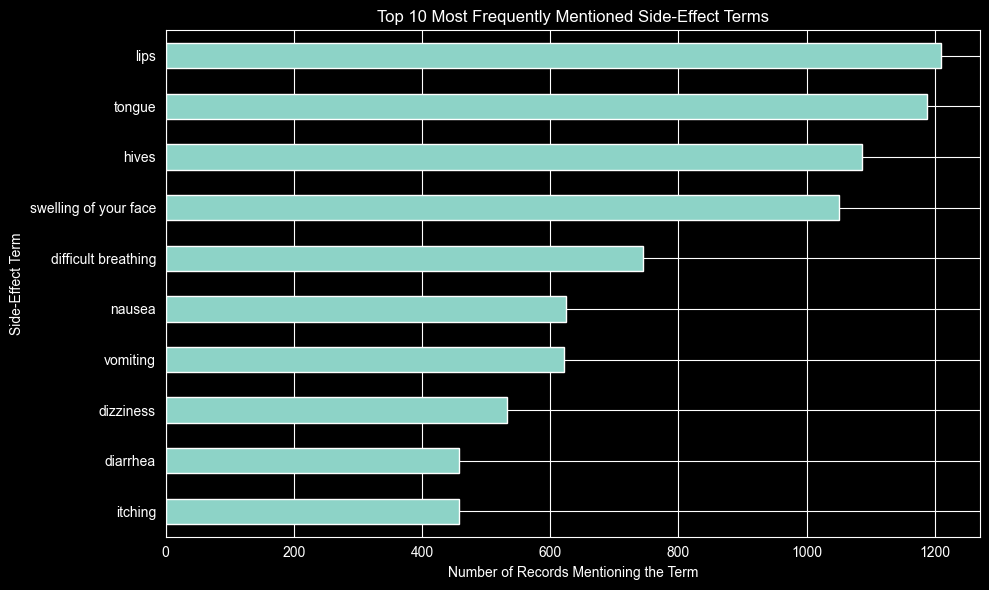

In [189]:
# Select the 10 most mentioned terms
top_effects = (
    side_effect_counts
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

top_effects.plot(kind="barh")

plt.title("Top 10 Most Frequently Mentioned Side-Effect Terms")
plt.xlabel("Number of Records Mentioning the Term")
plt.ylabel("Side-Effect Term")

plt.tight_layout()
plt.show()

as we can see that the most common side effect from all the drugs is lips then tongue then hives, which could indicate that these side effects arent dangerous to the patient without reviewing it with real doctor.

In [190]:
# Count distinct recorded side-effect terms for each drug
drug_effect_summary = (
    side_effects_long
    .drop_duplicates(["drug_name", "side_effect"])
    .groupby("drug_name")["side_effect"]
    .nunique()
    .sort_values(ascending=True)
)

# Display the 10 drugs with the fewest recorded terms
print(drug_effect_summary.head(10))

drug_name
ubrogepant                           1
guselkumab                           1
Limbrel                              2
Oxtellar XR                          3
Qelbree                              3
QuilliChew ER                        4
Fiorinal                             4
electrolyte replacement solutions    5
Zilretta                             5
salicylic acid/sulfur                5
Name: side_effect, dtype: int64


In [191]:
# Get the first 10 candidate drug names
candidate_drugs = drug_effect_summary.head(10).index

# Inspect their recorded descriptions
candidate_details = (
    dfcleaned[
        dfcleaned["drug_name"].isin(candidate_drugs)
    ][["drug_name", "medical_condition", "side_effects"]]
    .drop_duplicates()
)

print(candidate_details.to_string(index=False))

                        drug_name medical_condition                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

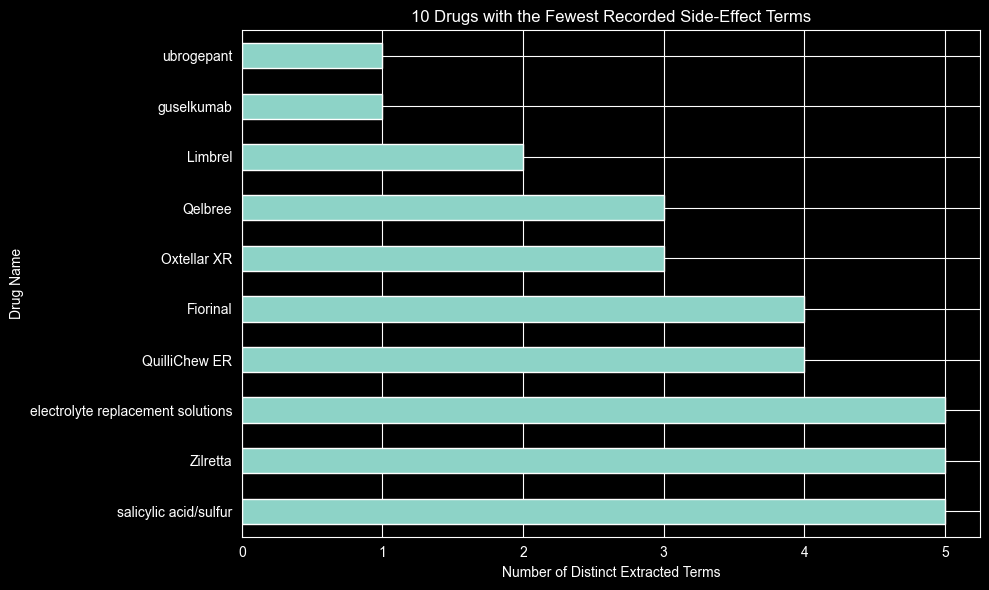

In [192]:
# Select the 10 drugs with the fewest distinct extracted terms
fewest_terms = drug_effect_summary.head(10).sort_values(
    ascending=False
)

# Create a horizontal bar chart to display least
plt.figure(figsize=(10, 6))

fewest_terms.plot(kind="barh")

plt.title("10 Drugs with the Fewest Recorded Side-Effect Terms")
plt.xlabel("Number of Distinct Extracted Terms")
plt.ylabel("Drug Name")

plt.tight_layout()
plt.show()

we can see that guselkumab ubrogepant are the lowest drugs in terms of side effects. however we cannot derive an insight that by using them means that you wont be affect at all.

#### Creating Target

In [193]:
side_effects_long = side_effects_long.copy()

side_effects_long["drug_name"] = (
    dfcleaned.loc[side_effects_long.index, "drug_name"].to_numpy()
)

side_effects_long["medical_condition"] = (
    dfcleaned.loc[side_effects_long.index, "medical_condition"].to_numpy()
)

In [194]:
serious_side_effects={
    "low":1,"moderate":2,"serious": 3
}
serious_medical_conditions={
    "low":1,"moderate":2,"serious": 3
}
light = ["nausea", "headache", "dry mouth","constipation", "sleepiness"]

moderate=["vomiting","diarrhea","stomach pain","flu-like symptoms","dizziness","rash","itching","throat irritation"]

extreme=["difficulty breathing","anaphylaxis","chest pain","seizures","severe skin reaction","severe weakness","muscle aches","unusual bruising","trouble swallowing"]

side_scores = []


for effect in side_effects_long["side_effect"]:

    effect = str(effect).lower()
    if any(word in effect for word in extreme):
        side_scores.append(3)

    elif any(word in effect for word in moderate):
        side_scores.append(2)

    elif any(word in effect for word in light):
        side_scores.append(1)

    else:
        side_scores.append(0)

side_effects_long["side_effect_score"] = pd.array(side_scores, dtype="Int64")

In [195]:
side_effects_long.columns

Index(['drug_name', 'side_effects', 'record_id', 'side_effect',
       'medical_condition', 'side_effect_score'],
      dtype='object')

In [196]:
df["medical_condition"].value_counts()

medical_condition
Pain                    264
Colds & Flu             245
Acne                    238
Hypertension            177
Osteoarthritis          129
Hayfever                124
Eczema                  122
AIDS/HIV                109
Diabetes (Type 2)       104
Psoriasis                93
GERD (Heartburn)         77
Pneumonia                72
Bronchitis               71
Angina                   71
Migraine                 61
Insomnia                 60
Constipation             60
Diabetes (Type 1)        57
Osteoporosis             56
ADHD                     55
Depression               51
Seizures                 50
Bipolar Disorder         47
UTI                      46
Asthma                   45
Cholesterol              45
Anxiety                  45
Diarrhea                 38
Covid 19                 34
Rheumatoid Arthritis     33
Alzheimer's              27
COPD                     23
Weight Loss              23
IBD (Bowel)              22
Cancer                   20
Sc

In [197]:
low_conditions = ["Acne","Pain","Colds & Flu","Hayfever","Insomnia","Constipation","Diarrhea","Allergies","Weight Loss","Erectile Dysfunction","Hair Loss"]
moderate_conditions = ["Osteoarthritis","Osteoporosis","Bronchitis","Migraine","GERD (Heartburn)","ADHD","Anxiety","Psoriasis","Eczema","UTI","Hypothyroidism","Gout","Herpes","Swine Flu","Incontinence","Gastrointestinal","Menopause","Cholesterol"]
serious_conditions = ["Diabetes (Type 2)","Stroke","Cancer","AIDS/HIV","Hypertension","Angina","Diabetes (Type 1)","Pneumonia","COPD","Asthma","Seizures","Alzheimer's","Schizophrenia","Bipolar Disorder","Covid 19","Depression","Rheumatoid Arthritis","IBD (Bowel)"]
condition_scores = []
for condition in side_effects_long["medical_condition"]:

    condition = str(condition).lower().strip()

    if condition in [c.lower() for c in serious_conditions]:
        condition_scores.append(3)

    elif condition in [c.lower() for c in moderate_conditions]:
        condition_scores.append(2)

    elif condition in [c.lower() for c in low_conditions]:
        condition_scores.append(1)

    else:
        condition_scores.append(0)

side_effects_long["condition_score"] = pd.array(
    condition_scores, dtype="Int64"
)


In [198]:
drug_condition_scores = (
    side_effects_long
    .groupby(["drug_name", "medical_condition"])
    .agg(
        side_effect_score=("side_effect_score", "max"),
        condition_score=("condition_score", "max")
    )
    .reset_index()
)

In [199]:
drug_condition_scores["avoid_drug"] = pd.NA

drug_condition_scores.loc[drug_condition_scores["side_effect_score"].isin([0,3]) ,"avoid_drug"] = 1 #avoid by default anything that isnt assigned

drug_condition_scores.loc[drug_condition_scores["side_effect_score"].isin([1, 2]),"avoid_drug"] = 0

drug_condition_scores["avoid_drug"] = (drug_condition_scores["avoid_drug"].astype("Int64"))


In [200]:
display(drug_condition_scores.head(100))
print(drug_condition_scores["avoid_drug"].value_counts(dropna=False))

,drug_name,medical_condition,side_effect_score,condition_score,avoid_drug
0,Abilify,Bipolar Disorder,3,3,1
1,Abilify Maintena,Bipolar Disorder,3,3,1
2,Abreva,Herpes,0,2,1
3,Absorica,Acne,3,1,1
4,Acanya,Acne,3,1,1
...,...,...,...,...,...
95,Azor,Hypertension,3,3,1
96,Azstarys,ADHD,2,2,0
97,BC Arthritis,Pain,2,1,0
98,BC Fast Pain Relief,Pain,3,1,1


avoid_drug
1    914
0    646
Name: count, dtype: Int64


In [201]:
drug_condition_scores

,drug_name,medical_condition,side_effect_score,condition_score,avoid_drug
0,Abilify,Bipolar Disorder,3,3,1
1,Abilify Maintena,Bipolar Disorder,3,3,1
2,Abreva,Herpes,0,2,1
3,Absorica,Acne,3,1,1
4,Acanya,Acne,3,1,1
...,...,...,...,...,...
1555,zoledronic acid,Osteoporosis,2,2,0
1556,zolmitriptan,Migraine,3,2,1
1557,zolpidem,Insomnia,3,1,1
1558,zonisamide,Seizures,3,3,1


In [202]:
dfcleaned = dfcleaned.drop(
    columns=[
        "side_effect_score",
        "condition_score",
        "condition_scores",
        "avoid_drug"
    ],
    errors="ignore"
)

In [203]:
dfcleaned = dfcleaned.merge(
    drug_condition_scores[
        [
            "drug_name",
            "medical_condition",
            "side_effect_score",
            "condition_score",
            "avoid_drug"
        ]
    ],
    on=["drug_name", "medical_condition"],
    how="left",
    validate="many_to_one"
)

In [204]:
print(dfcleaned["avoid_drug"].value_counts(dropna=False))

avoid_drug
1    915
0    647
Name: count, dtype: Int64


In [205]:
dfcleaned.columns

Index(['drug_name', 'medical_condition', 'side_effects', 'generic_name',
       'drug_classes', 'brand_names', 'activity', 'rx_otc',
       'pregnancy_category', 'csa', 'related_drugs',
       'medical_condition_description', 'rating', 'no_of_reviews',
       'new_rating', 'new_no_of_reviews', 'side_effect_score',
       'condition_score', 'avoid_drug'],
      dtype='object')

In [206]:
dfcleaned.to_csv("cleaned_drugs_v2.csv",index=False)

In [207]:
dfcleanedNew=pd.read_csv(r"C:\Users\abdal\PycharmProjects\AI_EDA\EDA_Project_Drugs\DataSet\cleaned_drugs_v2.csv")

### 3-Which drugs should be avoided because they frequently produce severe side effects?


In [208]:
# Potential serious-warning terms to investigate as a dictionary
warning_patterns = {
    "Breathing difficulties":
        r"shortness of breath|difficulty breathing|difficult breathing|trouble breathing",

    "Severe allergic reaction":
        r"anaphylaxis|severe allergic reaction",

    "Swelling of face or throat":
        r"swelling of (the )?(face|lips|tongue|throat)",

    "Chest pain":
        r"chest pain",

    "Seizures":
        r"\bseizures?\b",

    "Suicidal thoughts":
        r"suicidal thoughts?|thoughts of suicide",

    "Abnormal heartbeat":
        r"irregular heartbeat|abnormal heart rhythm",

    "Unusual bleeding":
        r"unusual bleeding|bleeding that won't stop|bleeding that will not stop",

    "Fainting":
        r"\bfainting\b|\bfaint\b"
}

In [209]:
# Keep distinct drug-description pairs
warning_data = (
    dfcleanedNew[["drug_name", "side_effects"]]
    .dropna(subset=["drug_name", "side_effects"])
    .drop_duplicates()
    .copy()
)

In [210]:
# Check whether each description mentions each warning category
for category, pattern in warning_patterns.items():
    warning_data[category] = warning_data["side_effects"].str.contains(pattern,case=False,regex=True,na=False)


C:\Users\abdal\AppData\Local\Temp\ipykernel_22584\2590975031.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  warning_data[category] = warning_data["side_effects"].str.contains(pattern,case=False,regex=True,na=False)


In [211]:
warning_columns = list(warning_patterns.keys())

# Count warning categories mentioned in each description
warning_data["warning_categories_mentioned"] = (
    warning_data[warning_columns].sum(axis=1)
)

warning_data["has_potential_warning"] = (
    warning_data["warning_categories_mentioned"] > 0
)

In [212]:
# Summarize the descriptions for each drug
drug_warning_summary = (
    warning_data.groupby("drug_name")
    .agg(
        descriptions_reviewed=("side_effects", "nunique"),
        descriptions_with_warning=("has_potential_warning", "sum"),
        warning_category_mentions=("warning_categories_mentioned", "sum")
    )
)

In [213]:
# Calculate the percentage of descriptions mentioning warning terms
drug_warning_summary["warning_description_percentage"] = (
    drug_warning_summary["descriptions_with_warning"]
    / drug_warning_summary["descriptions_reviewed"]
    * 100
)


In [214]:
# Inspect drugs with the highest percentage of descriptions mentioning warnings
# Require at least 2 distinct descriptions for this comparison
eligible_drugs = drug_warning_summary[
    drug_warning_summary["descriptions_reviewed"] >= 2
]
top_warning_drugs = eligible_drugs.sort_values(
    ["warning_description_percentage", "descriptions_reviewed"],
    ascending=[False, False]
).head(10)

print(top_warning_drugs)

                descriptions_reviewed  descriptions_with_warning  \
drug_name                                                          
triamcinolone                       3                          3   
acyclovir                           2                          2   
beclomethasone                      2                          2   
budesonide                          2                          2   
ciclesonide                         2                          2   
clindamycin                         2                          2   
cromolyn                            2                          2   
diclofenac                          2                          2   
erythromycin                        2                          2   
minocycline                         2                          2   

                warning_category_mentions  warning_description_percentage  
drug_name                                                                  
triamcinolone                  

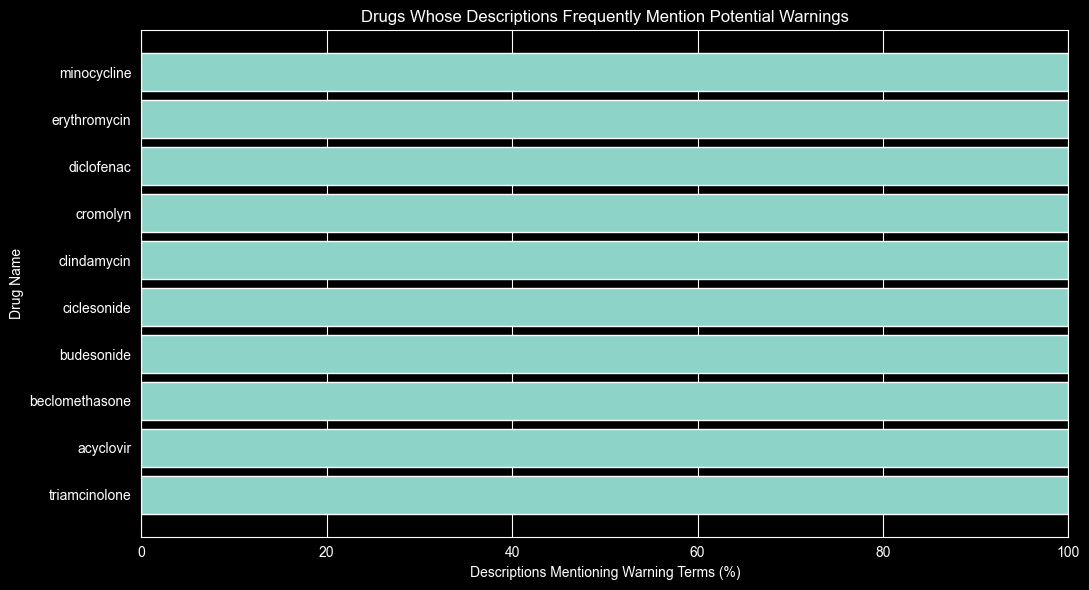

In [215]:
if not top_warning_drugs.empty:

    plot_data = top_warning_drugs.sort_values(
        "warning_description_percentage",
        ascending=True
    )

    plt.figure(figsize=(11, 6))

    plt.barh(
        plot_data.index,
        plot_data["warning_description_percentage"]
    )

    plt.title("Drugs Whose Descriptions Frequently Mention Potential Warnings")
    plt.xlabel("Descriptions Mentioning Warning Terms (%)")
    plt.ylabel("Drug Name")
    plt.xlim(0, 100)

    plt.tight_layout()
    plt.show()

else:
    print(
        "There are not enough drugs with multiple distinct descriptions "
        "for this percentage-based comparison."
    )

As you can see from the plot that anything that causes any discomfort to the patient is considered a problem.
though it is not a measure of how often patients experience these effects doctors should still take them into consideration when prescribing medical drugs.

### 4-How does the ratings vary across the available drugs and medical conditions?


In [216]:
# Keep records with available ratings
rating_data = dfcleanedNew.dropna(
    subset=["new_rating", "medical_condition", "drug_name"]
).copy()

# Summarize ratings by medical condition
condition_ratings = (
    rating_data.groupby("medical_condition")
    .agg(
        mean_rating=("new_rating", "mean"),
        median_rating=("new_rating", "median"),
        rating_count=("new_rating", "count")
    )
    .sort_values("mean_rating", ascending=False)
)

print(condition_ratings)

                      mean_rating  median_rating  rating_count
medical_condition                                             
Swine Flu                8.650000           8.65             4
Gout                     8.525000           8.25             8
Eczema                   8.269444           8.95            36
Pneumonia                8.027273           8.00            11
Stroke                   7.866667           7.20             3
Angina                   7.830000           8.80            20
Anxiety                  7.795455           8.05            44
Migraine                 7.728000           8.30            50
Herpes                   7.690000           8.30            10
Weight Loss              7.566667           7.55            18
Acne                     7.525000           7.60           116
Erectile Dysfunction     7.366667           7.80            12
IBD (Bowel)              7.330000           7.75            10
Asthma                   7.230303           7.10       

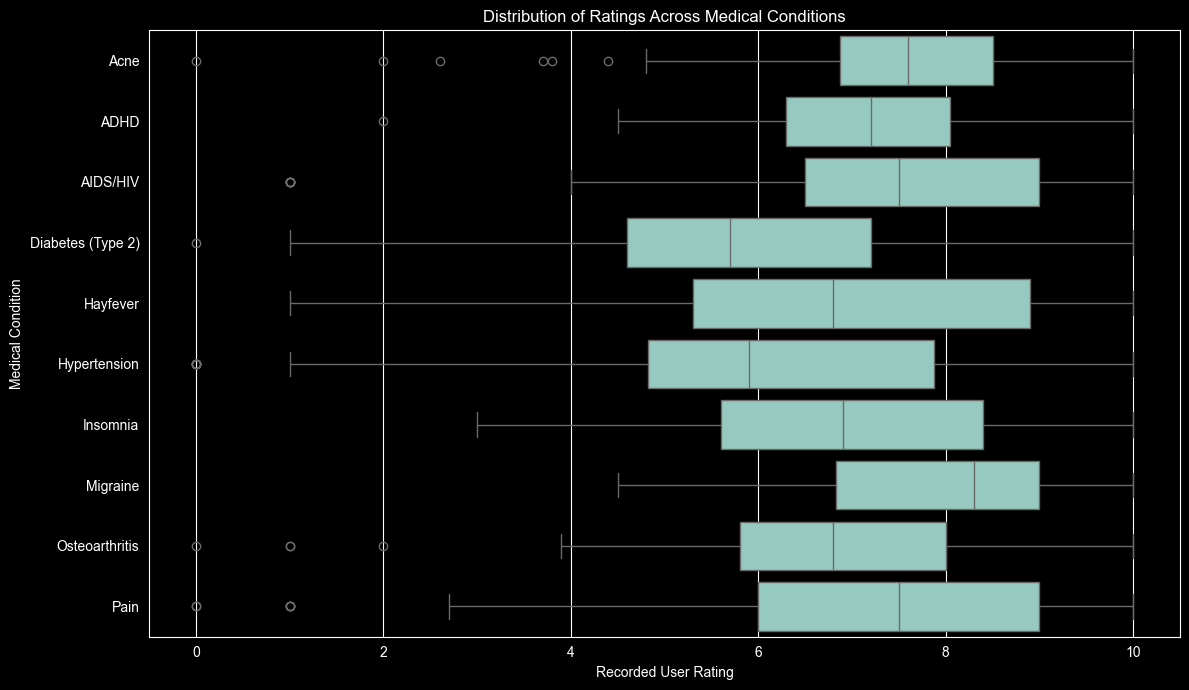

In [217]:
# Select the 10 conditions with the most recorded ratings
top_conditions = (
    condition_ratings.nlargest(10, "rating_count").index
)

plot_data = rating_data[
    rating_data["medical_condition"].isin(top_conditions)
]

plt.figure(figsize=(12, 7))

sb.boxplot(
    data=plot_data,
    x="new_rating",
    y="medical_condition"
)

plt.title("Distribution of Ratings Across Medical Conditions")
plt.xlabel("Recorded User Rating")
plt.ylabel("Medical Condition")
plt.tight_layout()
plt.show()

as you can see the ratings of these drugs related to the conditions pretty wise disturbution of 6 to 9 ratings that have not been affected by said sideeffects


### 5-How much overlap exists between the two datasets, and how reliably can medications and medical conditions be matched?(impossible to do since i ran out of time to combine other dataset but would like to explore later)